# **Bitcoin Energy Consumption and Price Clustering Analysis with Causality Testing**

## **Objective**
The objective of this experiment is to analyze the relationship between Bitcoin energy consumption, ESG index, carbon emissions, and Bitcoin price. The study applies **K-Means clustering** to identify potential market patterns and **Granger causality tests** to examine whether energy consumption can predict Bitcoin price fluctuations.

---

## **Data Processing**
### **Data Sources**
The datasets used in this experiment cover Bitcoin and Ethereum energy consumption, Bitcoin price, ESG stock index, and carbon emissions.

### **Preprocessing Steps**
1. **Standardizing date formats:** All datasets are converted to a common datetime format and set as the index.
2. **Column renaming:** Adjusted column names for clarity.
3. **Feature selection:** Retained only relevant features such as energy consumption, Bitcoin price, and ESG index.
4. **Data cleaning:** Converted price data to numeric format and removed missing values.
5. **Data merging:** Merged all datasets using the date index.

---

## **Clustering Analysis**
### **Feature Selection**
The following features are selected for clustering analysis:
- Estimated Bitcoin energy consumption (TWh per year)
- Minimum Bitcoin energy consumption (TWh per year)
- Annual global energy consumption (TWh)
- S&P World ESG Index (USD)
- Bitcoin carbon emissions (MtCO₂e)
- Bitcoin price (USD)

### **Standardization**
To ensure comparability, all selected features are standardized using **z-score normalization**:

$$
X_{\text{scaled}} = \frac{X - \mu}{\sigma}
$$

where \( \mu \) is the mean and \( \sigma \) is the standard deviation.

### **Elbow Method for Optimal \( K \)**
The elbow method is applied to determine the optimal number of clusters. The sum of squared errors (SSE) is computed for cluster values ranging from \( K = 2 \) to \( K = 10 \), and the optimal \( K \) is selected at the point where the SSE curve starts flattening.

$$
\text{SSE} = \sum_{i=1}^{K} \sum_{j \in C_i} || X_j - \mu_i ||^2
$$

where \( \mu_i \) is the centroid of cluster \( C_i \).

### **K-Means Clustering**
With the optimal \( K \) selected, K-Means clustering is performed to assign data points to clusters.

$$
\mu_i = \frac{1}{|C_i|} \sum_{j \in C_i} X_j
$$

Each data point is assigned to the nearest centroid, and the centroids are updated iteratively.

### **Silhouette Score**
To evaluate clustering performance, the **silhouette score** is calculated:

$$
s(i) = \frac{b(i) - a(i)}{\max(a(i), b(i))}
$$

where:
- \( a(i) \) is the average intra-cluster distance,
- \( b(i) \) is the average inter-cluster distance.

---

## **Principal Component Analysis (PCA)**
Since the original data is multi-dimensional, PCA is applied to reduce dimensionality to 3 components for visualization.

$$
X_{\text{PCA}} = X W
$$

where \( W \) is the matrix of principal component eigenvectors.

A scatter plot is generated to visualize the clustering results.

---

## **Cluster Analysis**
The mean values of each feature are computed for different clusters. This helps identify patterns in energy consumption, Bitcoin price, and carbon emissions across different market regimes.

$$
\mu_{C_i} = \frac{1}{|C_i|} \sum_{j \in C_i} X_j
$$

Bar plots are generated to compare feature mean values across clusters, using a log scale to accommodate large value differences.

---

## **Granger Causality Test**
To examine whether Bitcoin energy consumption **Granger-causes** Bitcoin price, the **Granger causality test** is conducted.

The test is performed on the following time series:
- \( Y_t \) (Bitcoin price)
- \( X_t \) (Estimated Bitcoin energy consumption)

The null hypothesis is:

$$
H_0: \text{Energy consumption does not Granger-cause Bitcoin price}
$$

The test involves fitting two autoregressive models:
1. **Restricted model** (without lagged values of \( X_t \)):

$$
Y_t = \alpha_0 + \sum_{i=1}^{p} \beta_i Y_{t-i} + \epsilon_t
$$

2. **Unrestricted model** (including lagged values of \( X_t \)):

$$
Y_t = \alpha_0 + \sum_{i=1}^{p} \beta_i Y_{t-i} + \sum_{i=1}^{p} \gamma_i X_{t-i} + \epsilon_t
$$

An F-test is used to compare the two models. If the p-value is below a significance threshold (\( p < 0.05 \)), we reject \( H_0 \), indicating that energy consumption Granger-causes Bitcoin price.

$$
F = \frac{\left( \text{RSS}_{\text{restricted}} - \text{RSS}_{\text{unrestricted}} \right) / p}{\text{RSS}_{\text{unrestricted}} / (n - 2p - 1)}
$$

where RSS is the residual sum of squares.

---

## **Results**
1. **Optimal Number of Clusters:** Based on the elbow method, the optimal cluster number is selected.
2. **Cluster Characteristics:** Clusters exhibit distinct patterns in Bitcoin energy consumption, ESG index, and Bitcoin price.
3. **Silhouette Score:** The clustering performance is evaluated.
4. **PCA Visualization:** A 2D scatter plot of clusters is presented.
5. **Granger Causality Test:** The test results indicate whether energy consumption predicts Bitcoin price.

---

## **Conclusion**
- **Clustering Analysis:** Identified different market regimes based on energy consumption and Bitcoin price.
- **Granger Causality Test:** Determined whether energy consumption has predictive power over Bitcoin price.
- **Practical Implications:** Findings could help investors and policymakers understand the role of energy consumption in cryptocurrency markets.

---

## **Future Work**
1. Explore **time-series clustering** techniques for dynamic patterns.
2. Integrate **deep learning models** to forecast Bitcoin price.
3. Extend the study to include additional cryptocurrencies (e.g., Ethereum).


C:\Users\why97\AppData\Local\Temp\ipykernel_20984\2447064847.py:46: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
Exception in thread Thread-4 (_readerthread):
Traceback (most recent call last):
  File "d:\anaconda\envs\shap\Lib\threading.py", line 1075, in _bootstrap_inner
    self.run()
  File "d:\anaconda\envs\shap\Lib\site-packages\ipykernel\ipkernel.py", line 766, in run_closure
    _threading_Thread_run(self)
  File "d:\anaconda\envs\shap\Lib\threading.py", line 1012, in run
    self._target(*self._args, **self._kwargs)
  File "d:\anaconda\envs\shap\Lib\subprocess.py", line 1599, in _readerthread
    buffer.append(fh.read())
                  ^^^^^^^^^
  File "<frozen codecs>", line 322, in decode
UnicodeDecodeError: 'utf-8' codec can't decode byte 0xbd in position 0: invalid start byte

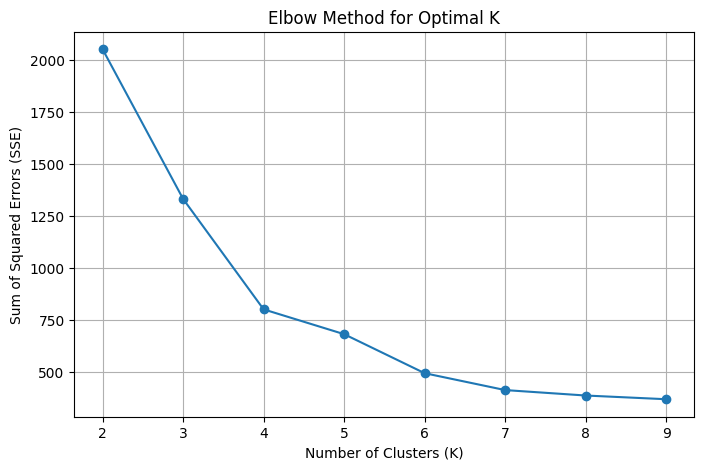

Silhouette Score: 0.49394136520827703


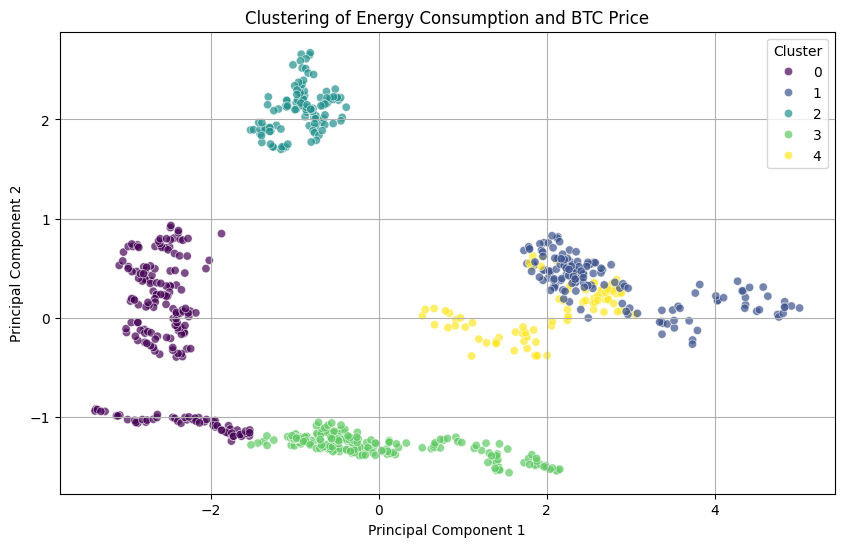

Cluster Means:
          Estimated TWh per Year  Minimum TWh per Year  \
Cluster                                                 
0                    114.966026             72.604905   
1                    172.196940            110.289470   
2                    204.495517             60.704577   
3                    116.257795            114.313083   
4                    151.995013             91.614065   

         S&P World ESG Index (USD)  Coal-only, MtCO2e         Price  
Cluster                                                              
0                       221.080909          90.972600  20468.342424  
1                       308.719610         155.256803  69125.168831  
2                       245.844087         105.309694  38763.750435  
3                       247.942160         129.211048  31010.981221  
4                       281.383820         166.235830  57868.764045  


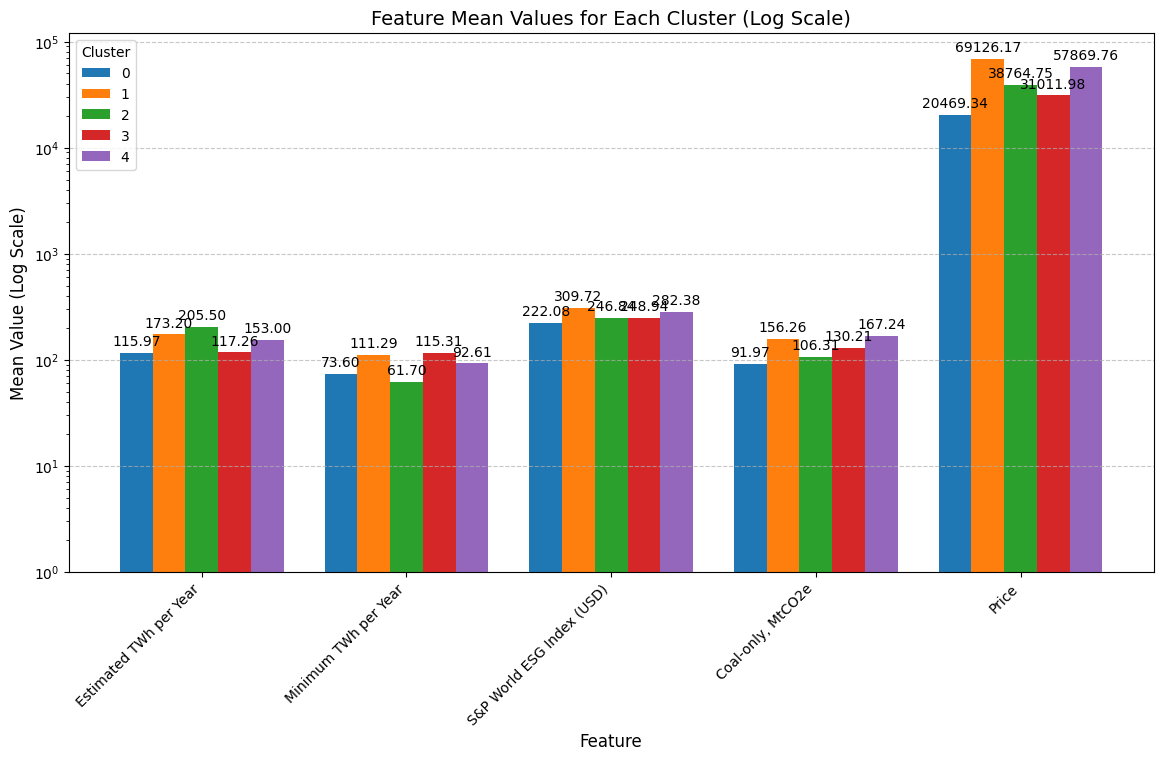

Granger Causality Test Results:

Granger Causality
number of lags (no zero) 1
ssr based F test:         F=11.2924 , p=0.0008  , df_denom=765, df_num=1
ssr based chi2 test:   chi2=11.3367 , p=0.0008  , df=1
likelihood ratio test: chi2=11.2539 , p=0.0008  , df=1
parameter F test:         F=11.2924 , p=0.0008  , df_denom=765, df_num=1

Granger Causality
number of lags (no zero) 2
ssr based F test:         F=4.4055  , p=0.0125  , df_denom=762, df_num=2
ssr based chi2 test:   chi2=8.8688  , p=0.0119  , df=2
likelihood ratio test: chi2=8.8179  , p=0.0122  , df=2
parameter F test:         F=4.4055  , p=0.0125  , df_denom=762, df_num=2

Granger Causality
number of lags (no zero) 3
ssr based F test:         F=2.8753  , p=0.0354  , df_denom=759, df_num=3
ssr based chi2 test:   chi2=8.7053  , p=0.0335  , df=3
likelihood ratio test: chi2=8.6562  , p=0.0342  , df=3
parameter F test:         F=2.8753  , p=0.0354  , df_denom=759, df_num=3

Granger Causality
number of lags (no zero) 4
ssr based F test

d:\anaconda\envs\shap\Lib\site-packages\statsmodels\tsa\stattools.py:1556: FutureWarning: verbose is deprecated since functions should not print results
  warnings.warn(


In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from statsmodels.tsa.stattools import grangercausalitytests

# Load the existing datasets
file_paths = {
    "bitcoin_energy": "bitcoin-energy-consumpti.csv",
    "btc_usd": "BTC_USD Bitfinex Historical Data (1).csv",
    "annual_energy": "Historical annualised electricity consumption.csv",
    "ESG_stock_index": "ESG stock index.csv",
    "eth_energy_pos": "Historical Ethereum network annualised electricity consumption (PoS).csv",
    "Bitcoin_gas_emissions": "Historical Bitcoin greenhouse gas emissions.csv"
}

dfs = {name: pd.read_csv(path, encoding="utf-8", low_memory=False) for name, path in file_paths.items()}

# Standardize date column names
dfs["bitcoin_energy"].rename(columns={"DateTime": "Date"}, inplace=True)
dfs["btc_usd"].rename(columns={"Date": "Date"}, inplace=True)
dfs["eth_energy_pos"].rename(columns={"Date and Time": "Date"}, inplace=True)
dfs["Bitcoin_gas_emissions"].rename(columns={"Date and Time": "Date"}, inplace=True)
dfs["annual_energy"].rename(columns={"Unnamed: 1": "Date"}, inplace=True)
dfs["ESG_stock_index"].rename(columns={"Date": "Date"}, inplace=True)

# Select relevant columns
dfs["bitcoin_energy"] = dfs["bitcoin_energy"][["Date", "Estimated TWh per Year", "Minimum TWh per Year"]]
dfs["btc_usd"] = dfs["btc_usd"][["Date", "Price"]]
dfs["eth_energy_pos"] = dfs["eth_energy_pos"][["Date", "annualised consumption GUESS, GWh"]]
dfs["annual_energy"] = dfs["annual_energy"][["Date", "Unnamed: 7"]]
dfs["ESG_stock_index"] = dfs["ESG_stock_index"][["Date", "S&P World ESG Index (USD)"]]
dfs["Bitcoin_gas_emissions"] = dfs["Bitcoin_gas_emissions"][["Date", "Coal-only, MtCO2e"]]

# Rename columns for clarity
dfs["annual_energy"].rename(columns={"Unnamed: 7": "Annual Energy Consumption (TWh)"}, inplace=True)
dfs["eth_energy_pos"].rename(columns={"annualised consumption GUESS, GWh": "Ethereum PoS Consumption (GWh)"}, inplace=True)

# Convert date columns to datetime format
for name, df in dfs.items():
    df["Date"] = pd.to_datetime(df["Date"], errors="coerce")
    df.set_index("Date", inplace=True)

# Convert price column to float and remove commas
dfs["btc_usd"]["Price"] = dfs["btc_usd"]["Price"].astype(str).str.replace(",", "").astype(float)

# Merge datasets on Date
merged_df = dfs["bitcoin_energy"].join([
    dfs["btc_usd"],
    dfs["eth_energy_pos"],
    dfs["annual_energy"],
    dfs["ESG_stock_index"],
    dfs["Bitcoin_gas_emissions"]
], how="inner")

# Drop NaN values
data_for_clustering = merged_df.dropna()

# Select features for clustering
features = ["Estimated TWh per Year", "Minimum TWh per Year", "Annual Energy Consumption (TWh)", "S&P World ESG Index (USD)", "Coal-only, MtCO2e", "Price"]
X = data_for_clustering[features]

# Standardize data
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Determine optimal number of clusters using the elbow method
sse = []
K_range = range(2, 10)  # Set range for K
for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42)
    kmeans.fit(X_scaled)
    sse.append(kmeans.inertia_)

# Plot elbow method graph
plt.figure(figsize=(8, 5))
plt.plot(K_range, sse, marker='o')
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Sum of Squared Errors (SSE)")
plt.title("Elbow Method for Optimal K")
plt.grid()
plt.show()

# Set optimal K value (adjust manually if needed)
num_clusters = 5

# Perform K-Means clustering
kmeans = KMeans(n_clusters=num_clusters, random_state=42)
clusters = kmeans.fit_predict(X_scaled)
X["Cluster"] = clusters.astype(int)

# Compute silhouette score
silhouette_avg = silhouette_score(X_scaled, clusters)
print(f"Silhouette Score: {silhouette_avg}")

# Perform PCA for visualization
pca = PCA(n_components=3)
X_pca = pca.fit_transform(X_scaled)

plt.figure(figsize=(10, 6))
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=clusters, palette="viridis", alpha=0.7)
plt.title("Clustering of Energy Consumption and BTC Price")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend(title="Cluster")
plt.grid()
plt.show()

# Compute mean values for each cluster
X_numeric = X.select_dtypes(include=[np.number])
cluster_means = X_numeric.groupby("Cluster").mean()
print("Cluster Means:\n", cluster_means)

# Visualize feature means for each cluster
# Plot
fig, ax = plt.subplots(figsize=(14, 7))

# Use log scale on the y-axis to handle large value differences
cluster_means.T.plot(kind="bar", ax=ax, width=0.8, log=True)

# Set titles and labels
plt.title("Feature Mean Values for Each Cluster (Log Scale)", fontsize=14)
plt.ylabel("Mean Value (Log Scale)", fontsize=12)
plt.xlabel("Feature", fontsize=12)

# Rotate x-axis labels for better readability
plt.xticks(rotation=45, ha='right')

# Add grid lines
plt.grid(axis='y', linestyle="--", alpha=0.7)

# Add legend
plt.legend(title="Cluster")

# Add value labels to bars
for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", fontsize=10, padding=3)

plt.show()

# Perform Granger causality test
max_lag = 5
print("Granger Causality Test Results:")
granger_results = grangercausalitytests(merged_df[["Estimated TWh per Year", "Price"]], max_lag, verbose=True)


### **Key Findings**

#### **1️⃣ K-Means Clustering Insights**
- **Bitcoin price, energy consumption, ESG index, and carbon emissions exhibit five distinct market regimes (clusters).**  
- **Significant differences exist between clusters:**
  - **Clusters 1 and 4 show high Bitcoin prices and high energy consumption**, suggesting that **Bitcoin markets may experience higher prices during periods of elevated mining activity**.
  - **Cluster 0 shows low energy consumption but still has notable price fluctuations**, indicating that other factors (e.g., regulations, investor sentiment) may drive the market.
- **Energy consumption patterns and carbon emissions correlate across clusters**, suggesting that **Bitcoin mining activity influences market states**.

#### **2️⃣ Granger Causality Test Findings**
- **Bitcoin energy consumption has a short-term predictive effect on Bitcoin price:**
  - **At lag 1 (\( p = 0.0008 \)) and lag 2 (\( p = 0.0125 \)), energy consumption significantly Granger-causes Bitcoin price**, indicating that **recent energy consumption changes can predict short-term price movements**.
  - **At lag 3 (\( p = 0.0354 \)), the effect is still present but weaker**.
  - **At lag 4 and beyond (\( p > 0.05 \)), the relationship is no longer statistically significant**, suggesting that **long-term Bitcoin prices are not directly influenced by past energy consumption**—other market factors (such as regulations and investor sentiment) may dominate.

### **Conclusion**
✅ **Bitcoin energy consumption has a short-term predictive impact on Bitcoin price (1-3 days), but its long-term influence is limited.**  
✅ **Market regimes (clusters) are strongly associated with Bitcoin price, energy consumption, and carbon emissions, with some clusters exhibiting high energy consumption and high prices.**  
✅ **Regulatory policies and investor awareness of energy consumption may have structural impacts on Bitcoin markets, warranting further research and monitoring.**